In [2]:
# BUSINESS SCIENCE -----
# LAB 90: CAUSAL INFERENCE IN PYTHON ----
# Part 2: SOLUTION: REDUCE HOTEL CANCELLATIONS -----
# *** ----
# Goals: -----
# - We have developed an experiment: Send a targeted offer to customers in Market Segment == "Groups" who book more than 90 days out
# - Offer 10% off (on average $1500 this costs hotel $150)
# - The population is 19811 customers over the period analyzed
# - The test population is 500 customers (250 control, 250 treatment)

# Questions: -----
# - What affect does this have on cancellations?
# - Is there a Return on Investment (ROI)?

# IMPORTANT: -----
# - This is a scenario that is post-treatment data analysis

In [3]:
!pip install causalml lightgbm

In [4]:
# LIBRARIES -----

import pandas as pd
import numpy as np
import pytimetk as tk
import matplotlib.pyplot as plt

from causalml.inference.tree import UpliftTreeClassifier # Allows us to find the 'lift' -> How much marketing dollars went to drive $
from causalml.inference.tree import uplift_tree_string, uplift_tree_plot
from causalml.inference.meta import BaseSClassifier, BaseTClassifier

from IPython.display import Image
from sklearn.model_selection import train_test_split
from lightgbm import LGBMClassifier

c:\Users\guske\Desktop\Python_Projects\Python_Projects_3\modern_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-01 12:56:19,514	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
Failed to import duecredit due to No module named 'duecredit'


In [5]:
# Data -----

hotel_experiment_df = pd.read_csv('data/hotel_cancellations_experiment.csv')

hotel_experiment_df.glimpse()

<class 'pandas.DataFrame'>: 500 rows of 18 columns
is_canceled:                     int64             [1, 1, 1, 0, 1, 1, 0, ...
deposit_type:                    object            ['Non Refund', 'Non R ...
previous_cancellations:          int64             [0, 0, 0, 0, 1, 0, 0, ...
lead_time:                       int64             [129, 143, 267, 173,  ...
total_of_special_requests:       int64             [0, 0, 0, 0, 0, 0, 0, ...
different_room_assigned:         int64             [0, 0, 0, 0, 0, 0, 0, ...
market_segment:                  object            ['Groups', 'Groups',  ...
required_car_parking_spaces:     int64             [0, 0, 0, 0, 0, 0, 0, ...
distribution_channel:            object            ['TA/TO', 'TA/TO', 'T ...
hotel:                           object            ['City Hotel', 'Resor ...
customer_type:                   object            ['Transient', 'Transi ...
previous_bookings_not_canceled:  int64             [0, 0, 0, 0, 0, 0, 0, ...
is_repeated_guest:       

In [6]:
df = hotel_experiment_df.copy()

df.glimpse()

<class 'pandas.DataFrame'>: 500 rows of 18 columns
is_canceled:                     int64             [1, 1, 1, 0, 1, 1, 0, ...
deposit_type:                    object            ['Non Refund', 'Non R ...
previous_cancellations:          int64             [0, 0, 0, 0, 1, 0, 0, ...
lead_time:                       int64             [129, 143, 267, 173,  ...
total_of_special_requests:       int64             [0, 0, 0, 0, 0, 0, 0, ...
different_room_assigned:         int64             [0, 0, 0, 0, 0, 0, 0, ...
market_segment:                  object            ['Groups', 'Groups',  ...
required_car_parking_spaces:     int64             [0, 0, 0, 0, 0, 0, 0, ...
distribution_channel:            object            ['TA/TO', 'TA/TO', 'T ...
hotel:                           object            ['City Hotel', 'Resor ...
customer_type:                   object            ['Transient', 'Transi ...
previous_bookings_not_canceled:  int64             [0, 0, 0, 0, 0, 0, 0, ...
is_repeated_guest:       

In [7]:
df['treatment_control'].value_counts()

treatment_control
control      250
treatment    250
Name: count, dtype: int64

In [8]:
# How many people recieved offers to rebook at a earlier date?

df['treatment_control'].value_counts()

treatment_control
control      250
treatment    250
Name: count, dtype: int64

In [9]:
# How many people accepted the offer?

df.groupby('treatment_control')['accept_offer'].sum()

df.groupby('treatment_control')['accept_offer'] \
    .agg(['sum', 'count']) \
    .assign(acceptance_rate=lambda x: x['sum'] / x['count'])

,sum,count,acceptance_rate
treatment_control,,,
control,0,250,0.000
treatment,62,250,0.248


In [10]:
# What is the average cancellation rate for each group?

df \
    .groupby('treatment_control')['is_canceled'] \
    .agg(['sum', 'count']) \
    .assign(cancellation_rate=lambda x: x['sum'] / x['count'])

,sum,count,cancellation_rate
treatment_control,,,
control,176,250,0.704
treatment,145,250,0.580


In [11]:
# Of the people who accepted the offer, what is their cancellation rate? -> This shows that the cancellation rate went way down when offer was accepted

df \
    .groupby(['treatment_control', 'accept_offer']) \
    ['is_canceled'] \
    .agg(['sum', 'count']) \
    .assign(cancellation_rate=lambda x: x['sum'] / x['count'])

sum  count  cancellation_rate
treatment_control accept_offer                               
control           0             176    250           0.704000
treatment         0             134    188           0.712766
                  1              11     62           0.177419

In [12]:
# 2.0 CAUSAL MACHINE LEARNING ANALYSIS -----

# Prep
df = hotel_experiment_df.copy()

df['conversion'] = (~df['is_canceled'].astype(bool)).astype(int)

df.drop(columns=['is_canceled', 'accept_offer', 'lead_time'], inplace=True)

df.glimpse()

df_processed = pd.get_dummies(
    df,
    columns=['deposit_type', 'market_segment', 'distribution_channel', 'hotel', 'customer_type'],
    drop_first=False,
    dtype=int
)

df_processed.glimpse()

<class 'pandas.DataFrame'>: 500 rows of 16 columns
deposit_type:                    object            ['Non Refund', 'Non R ...
previous_cancellations:          int64             [0, 0, 0, 0, 1, 0, 0, ...
total_of_special_requests:       int64             [0, 0, 0, 0, 0, 0, 0, ...
different_room_assigned:         int64             [0, 0, 0, 0, 0, 0, 0, ...
market_segment:                  object            ['Groups', 'Groups',  ...
required_car_parking_spaces:     int64             [0, 0, 0, 0, 0, 0, 0, ...
distribution_channel:            object            ['TA/TO', 'TA/TO', 'T ...
hotel:                           object            ['City Hotel', 'Resor ...
customer_type:                   object            ['Transient', 'Transi ...
previous_bookings_not_canceled:  int64             [0, 0, 0, 0, 0, 0, 0, ...
is_repeated_guest:               int64             [0, 0, 0, 0, 0, 0, 0, ...
country_PRT:                     int64             [1, 1, 1, 1, 1, 1, 1, ...
country_other:           

In [13]:
# * Uplift Tree -----
# # https://causalml.readthedocs.io/en/latest/methodology.html#tree-based-algorithms

# Split data to training and testing samples for model validation (next section)
df_train, df_test = train_test_split(
    df_processed, 
    test_size=0.2, 
    random_state=111
)

In [14]:
# Train uplift tree
uplift_model = UpliftTreeClassifier(
    max_depth=4, 
    min_samples_leaf=200, 
    min_samples_treatment=50, 
    n_reg=100, 
    evaluationFunction='KL', 
    control_name='control'
)

In [15]:
# Specify columns to be used for training
x_names = [
    'previous_cancellations', 'total_of_special_requests',
    'different_room_assigned', 'required_car_parking_spaces',
    'previous_bookings_not_canceled', 'is_repeated_guest', 'country_PRT',
    'country_other', 'new_lead_time',
    'deposit_type_No Deposit', 'deposit_type_Non Refund',
    'deposit_type_Refundable', 'market_segment_Groups',
    'distribution_channel_Corporate', 'distribution_channel_Direct',
    'distribution_channel_TA/TO', 'hotel_City Hotel', 'hotel_Resort Hotel',
    'customer_type_Contract', 'customer_type_Transient',
    'customer_type_Transient-Party'
]

In [16]:
# Train uplift tree
uplift_model = UpliftTreeClassifier(
    max_depth = 4, 
    min_samples_leaf = 20,
    min_samples_treatment = 10,
    n_reg = 0,
    evaluationFunction='KL', # The Kullback-Leibler (KL) divergence
    control_name='control'
)

uplift_model.fit(df_train[x_names].values,
                 treatment=df_train['treatment_control'].values,
                 y=df_train['conversion'].values)

,control_name,'control'
,max_depth,4
,min_samples_leaf,20
,n_reg,0
,max_features,None
,min_samples_treatment,10
,early_stopping_eval_diff_scale,1
,evaluationFunction,'KL'
,normalization,True
,honesty,False
,estimation_sample_size,0.5


In [17]:
# Print uplift tree as a string
result = uplift_tree_string(uplift_model.fitted_uplift_tree, x_names)

new_lead_time >= 97.5?
yes -> new_lead_time >= 422.5?
		yes -> [np.float64(0.24), np.float64(0.5454545454545454)]
		no  -> new_lead_time >= 255.5?
				yes -> new_lead_time >= 325.0?
						yes -> [np.float64(0.3), np.float64(0.19230769230769232)]
						no  -> [np.float64(0.13953488372093023), np.float64(0.35)]
				no  -> new_lead_time >= 164.5?
						yes -> [np.float64(0.475), np.float64(0.21212121212121213)]
						no  -> [np.float64(0.35185185185185186), np.float64(0.4117647058823529)]
no  -> [np.float64(0.4), np.float64(0.7567567567567568)]


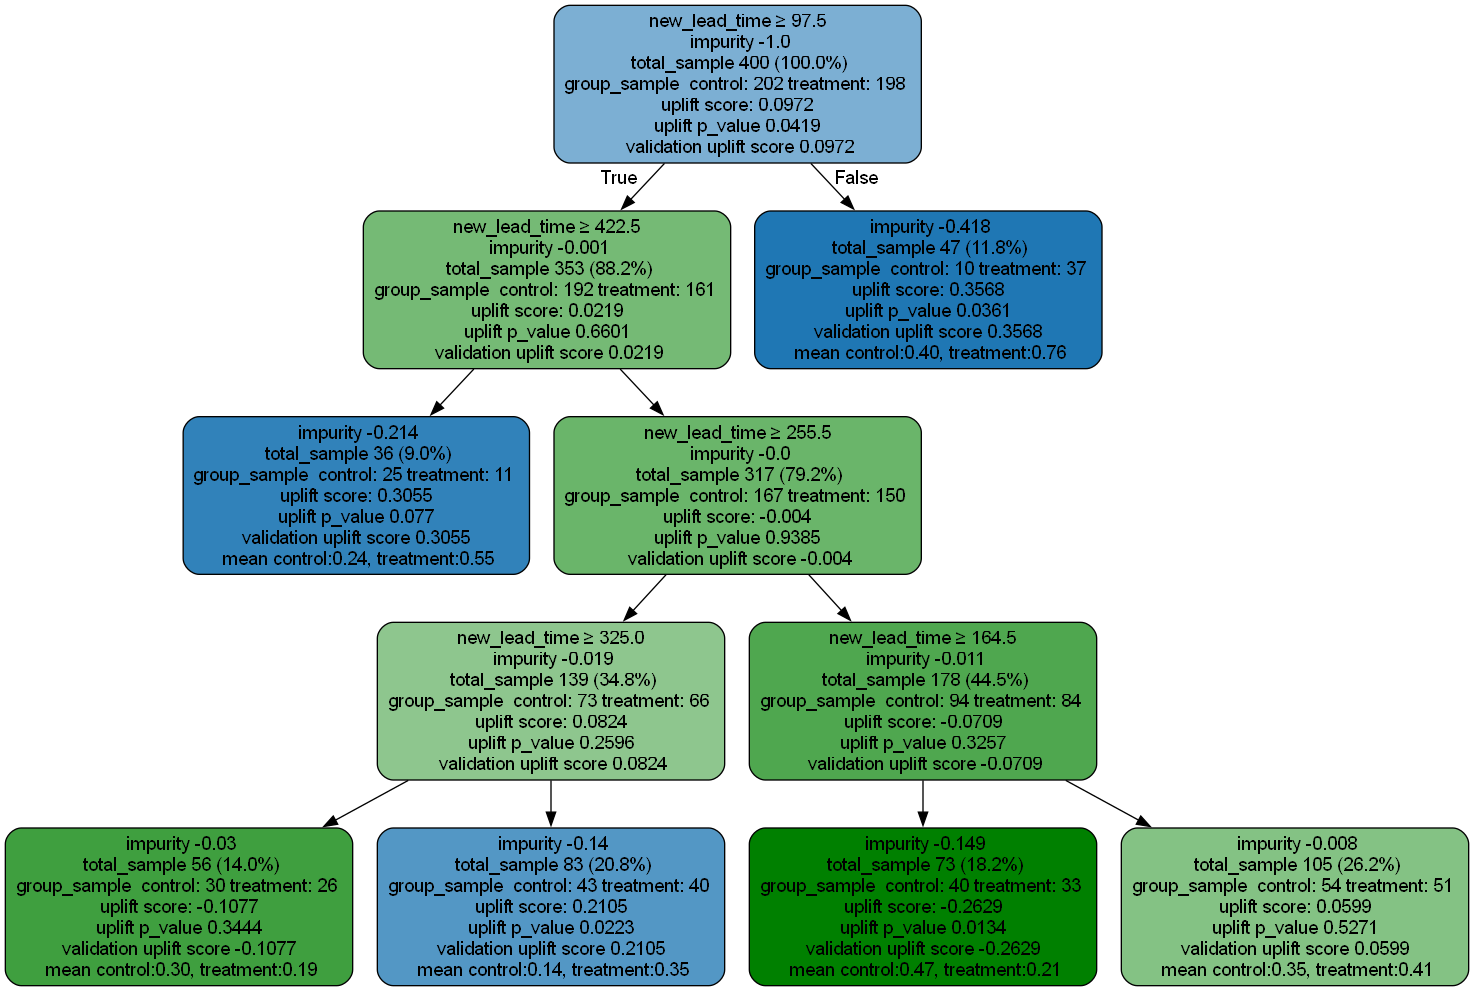

In [18]:
import os

# Explicitly add the standard Graphviz installation path to Python's environment PATH
graphviz_bin_path = r"C:\Program Files\Graphviz\bin"
if os.path.exists(graphviz_bin_path) and graphviz_bin_path not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + graphviz_bin_path
    
# Plot uplift tree -> This graph shows a visual of the decision tree -> Calculates uplift score
graph = uplift_tree_plot(uplift_model.fitted_uplift_tree, x_names)
Image(graph.create_png())

<Axes: >

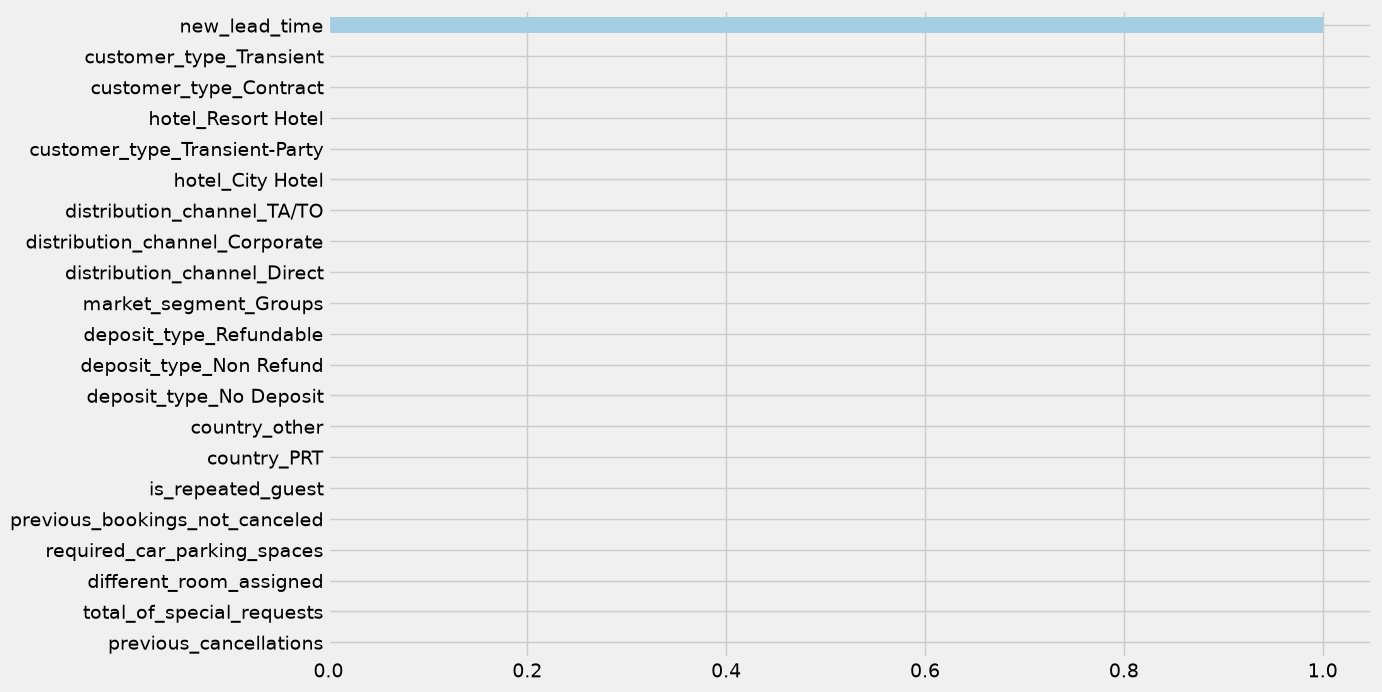

In [19]:
# Uplift Tree Importances (Interpretable CausalML)
pd.Series(uplift_model.feature_importances_, index=x_names).sort_values().plot(kind='barh', figsize=(12,8))

[LightGBM] [Info] Number of positive: 144, number of negative: 256
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000259 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 132
[LightGBM] [Info] Number of data points in the train set: 400, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.360000 -> initscore=-0.575364
[LightGBM] [Info] Start training from score -0.575364
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf

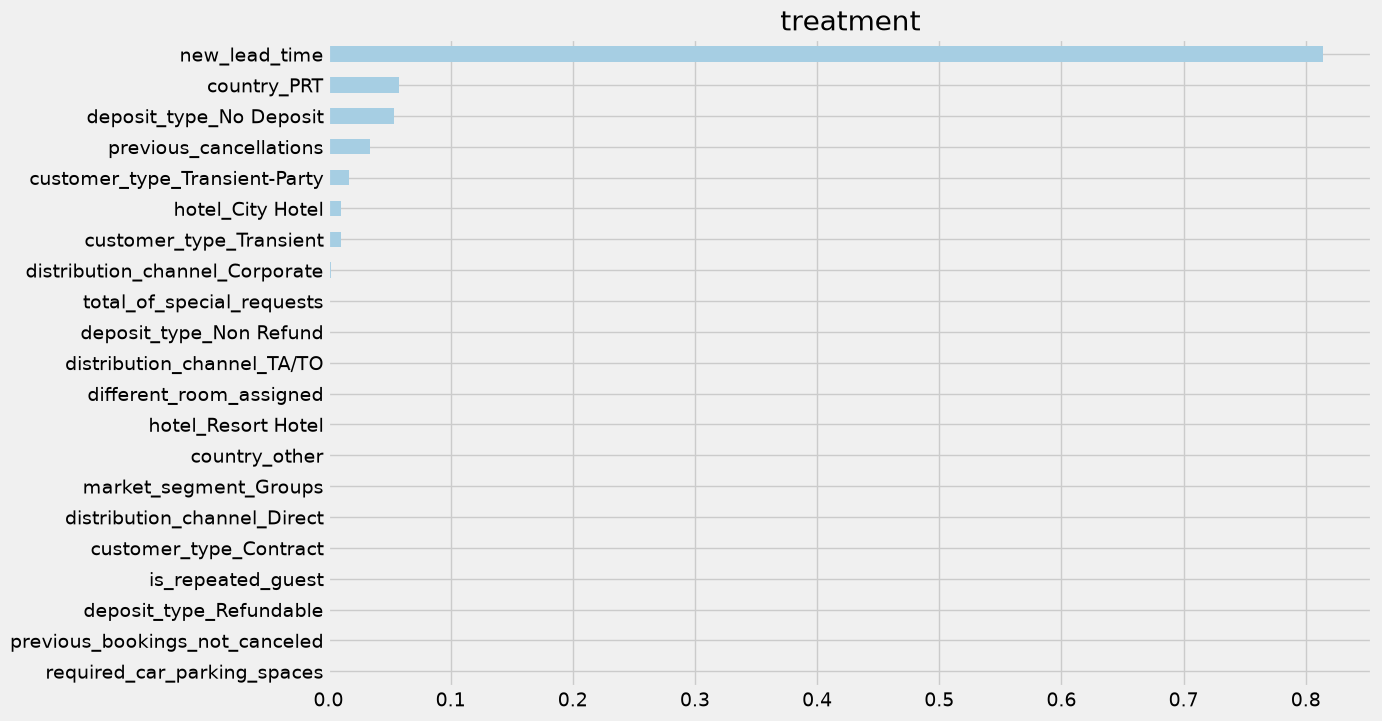

In [20]:
# * Interpretable CausalML -----
# # https://causalml.readthedocs.io/en/latest/methodology.html#s-learner
# # https://causalml.readthedocs.io/en/latest/interpretation.html

slearner = BaseSClassifier(learner=LGBMClassifier(), control_name='control')

slearner.estimate_ate(
    df_train[x_names].values, 
    df_train['treatment_control'].values, 
    df_train['conversion'].values
)

slearner_tau = slearner.fit_predict(
    df_train[x_names].values, 
    df_train['treatment_control'].values, 
    df_train['conversion'].values
)

# Conditional Average Treatment Effects (CATE, denoted Tau)
slearner_tau

slearner.get_importance(
    X=df_train[x_names].values, 
    tau=slearner_tau, 
    normalize=True, 
    method='auto', 
    features=x_names
)

slearner.plot_importance(
    X=df_train[x_names].values, 
    tau=slearner_tau, 
    normalize=True, 
    method='auto', 
    features=x_names
)


[LightGBM] [Warning] There are no meaningful features which satisfy the provided configuration. Decreasing Dataset parameters min_data_in_bin or min_data_in_leaf and re-constructing Dataset might resolve this warning.
[LightGBM] [Info] Total Bins 0
[LightGBM] [Info] Number of data points in the train set: 2, number of used features: 0
[LightGBM] [Info] Start training from score 0.500000
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split

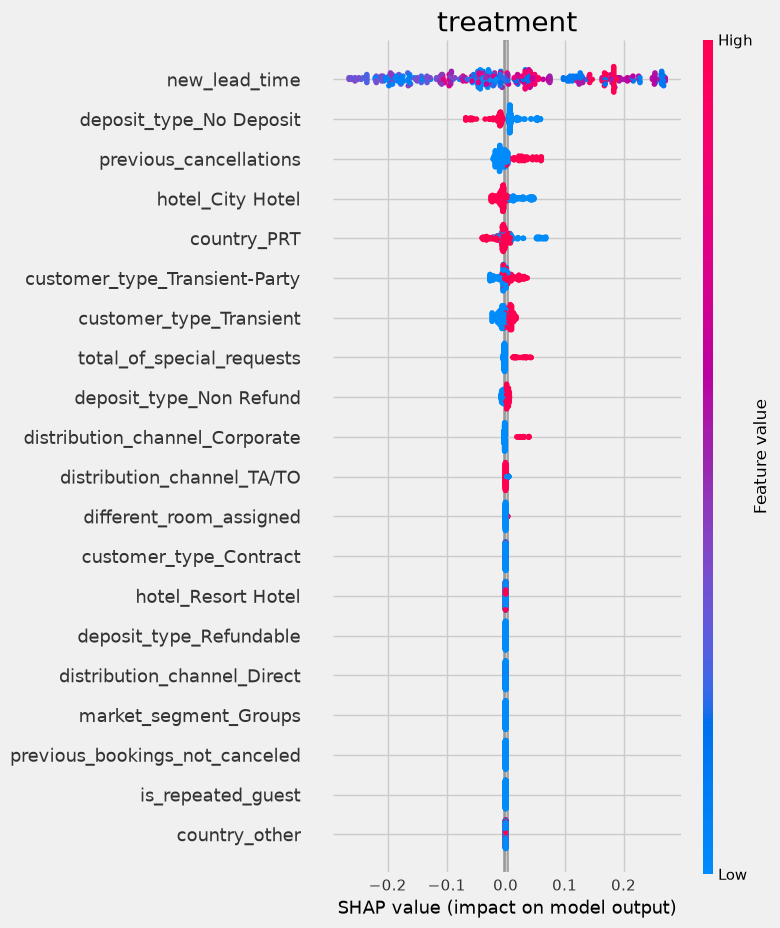

[LightGBM] [Warning] There are no meaningful features which satisfy the provided configuration. Decreasing Dataset parameters min_data_in_bin or min_data_in_leaf and re-constructing Dataset might resolve this warning.
[LightGBM] [Info] Total Bins 0
[LightGBM] [Info] Number of data points in the train set: 2, number of used features: 0
[LightGBM] [Info] Start training from score 0.500000
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split

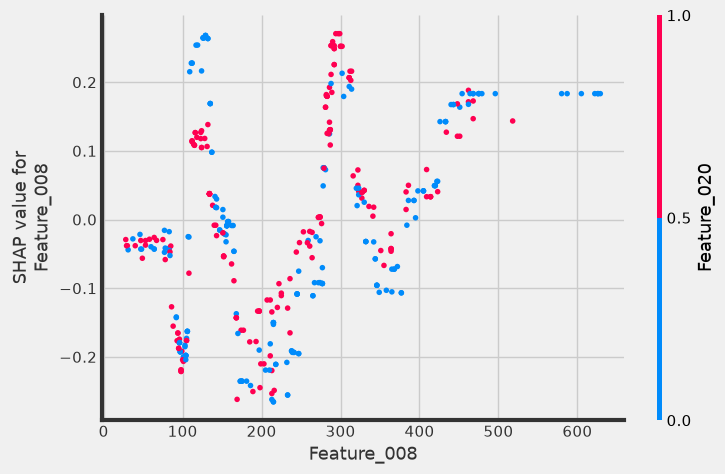

[LightGBM] [Warning] There are no meaningful features which satisfy the provided configuration. Decreasing Dataset parameters min_data_in_bin or min_data_in_leaf and re-constructing Dataset might resolve this warning.
[LightGBM] [Info] Total Bins 0
[LightGBM] [Info] Number of data points in the train set: 2, number of used features: 0
[LightGBM] [Info] Start training from score 0.500000
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split

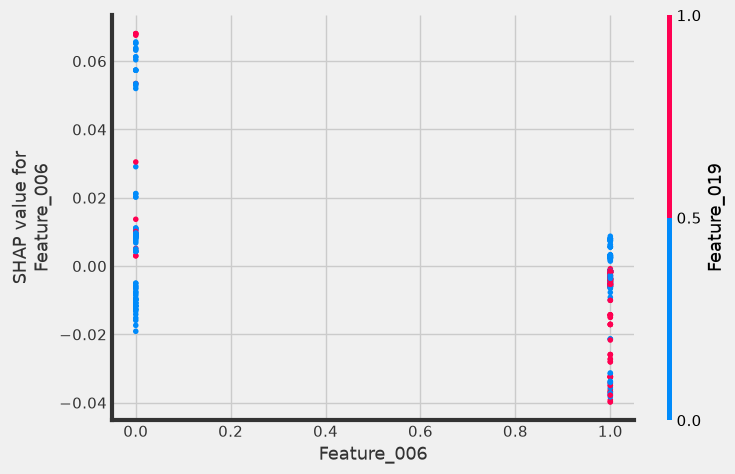

In [21]:
slearner.get_shap_values(
    X=df_train[x_names].values, 
    tau=slearner_tau
)

slearner.plot_shap_values(
    X=df_train[x_names].values, 
    tau=slearner_tau, 
    features=x_names
)

# New Lead Time (Index 8)
slearner.plot_shap_dependence(
    treatment_group='treatment', 
    feature_idx=8, 
    X=df_train[x_names].values, 
    tau=slearner_tau, 
    interaction_idx='auto'
)

# country_PRT (Index 6)
slearner.plot_shap_dependence(
    treatment_group='treatment', 
    feature_idx=6, 
    X=df_train[x_names].values, 
    tau=slearner_tau, 
    interaction_idx='auto'
)

In [22]:
# * Optimize for Conversion -----
# # https://github.com/uber/causalml/blob/master/docs/examples/counterfactual_value_optimization.ipynb

from causalml.inference.meta import BaseTClassifier
from causalml.optimize import get_treatment_costs
from causalml.optimize import get_actual_value

# Put costs into dicts
conversion_cost_dict = {'control': 0, 'treatment': 150} #The treatment cost is if they take the deal there is a $150 cost (10% of average cost)
impression_cost_dict = {'control': 0, 'treatment': 0}

# Use a helper function to put treatment costs to array
cc_array, ic_array, conditions = get_treatment_costs(
    treatment=df_processed['treatment_control'],
    control_name='control',
    cc_dict=conversion_cost_dict,
    ic_dict=impression_cost_dict
)

# Put the conversion value array into an array
conversion_value_array = np.full(df.shape[0], 1500)

(array([321.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 179.]),
 array([   0.,  150.,  300.,  450.,  600.,  750.,  900., 1050., 1200.,
        1350., 1500.]),
 <BarContainer object of 10 artists>)

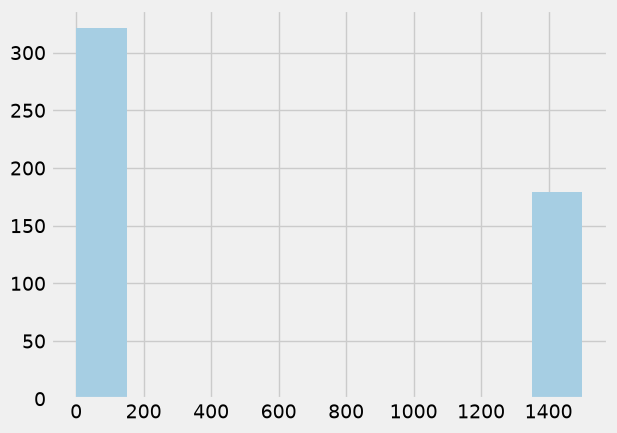

In [23]:
# Use a helper function to obtain the value of
# actual treatment
actual_value = get_actual_value(
    treatment=df_processed['treatment_control'],
    observed_outcome=df_processed['conversion'],
    conversion_value=conversion_value_array,
    conditions=conditions,
    conversion_cost=cc_array,
    impression_cost=ic_array
)

plt.hist(actual_value)


In [24]:
df_train, df_test = train_test_split(
    df_processed, test_size=0.2, random_state=111
)
train_idx = df_train.index
test_idx = df_test.index

In [25]:
# Calculate the benchmark value according to the
# random allocation
# and best treatment schemes
random_allocation_value = actual_value.loc[test_idx].mean() #Go after people randomly

best_ate = df_train.groupby('treatment_control')['conversion'].mean().idxmax() #Best average treatment effect

actual_is_best_ate = df_test['treatment_control'] == best_ate #Assign based on ML

best_ate_value = actual_value.loc[test_idx][actual_is_best_ate].mean()

# Calculate the value under an uplift model
tm = BaseTClassifier(
    control_learner=LGBMClassifier(), 
    treatment_learner=LGBMClassifier(), 
    control_name='control'
)

tm.fit(
    df_train[x_names].values, 
    df_train['treatment_control'].values, 
    df_train['conversion'].values
)

tm_pred = tm.predict(df_test[x_names].values)

pred_df = pd.DataFrame(tm_pred, columns=tm._classes)
tm_best = pred_df.idxmax(axis=1)

# Use .to_numpy() instead of .ravel()
actual_is_tm_best = df_test['treatment_control'] == tm_best.to_numpy()

tm_value = actual_value.loc[test_idx][actual_is_tm_best].mean()

[LightGBM] [Info] Number of positive: 63, number of negative: 139
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000087 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 76
[LightGBM] [Info] Number of data points in the train set: 202, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.311881 -> initscore=-0.791339
[LightGBM] [Info] Start training from score -0.791339
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[

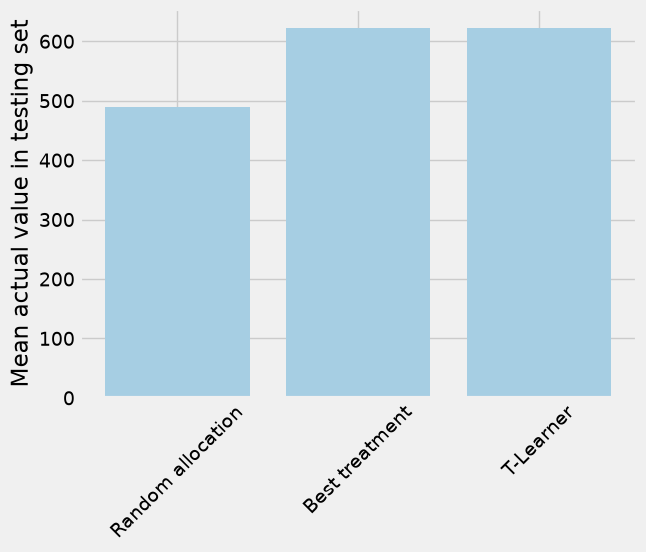

In [26]:
# Plot the results -> Shows the difference in money saved per person
labels = [
    'Random allocation',
    'Best treatment',
    'T-Learner',
]

values = [
    random_allocation_value,
    best_ate_value,
    tm_value,
]

plt.bar(labels, values)
plt.ylabel('Mean actual value in testing set')
plt.xticks(rotation=45)
plt.show()

In [27]:
# 3.0 UPLIFT: BACK TO BASICS ----- Doing the calculations manually

df = hotel_experiment_df.copy()

# How many people accepted the offer?
df.groupby('treatment_control')['accept_offer'] \
    .agg(['sum', 'count']) \
    .assign(acceptance_rate=lambda x: x['sum'] / x['count'])

,sum,count,acceptance_rate
treatment_control,,,
control,0,250,0.000
treatment,62,250,0.248


In [28]:
# How many people cancelled?
df \
    .groupby(['treatment_control', 'accept_offer'])['is_canceled'] \
    .agg(['sum', 'count']) \
    .assign(cancellation_rate=lambda x: x['sum'] / x['count'])

sum  count  cancellation_rate
treatment_control accept_offer                               
control           0             176    250           0.704000
treatment         0             134    188           0.712766
                  1              11     62           0.177419

In [29]:
# * Lift Calculation -----
# All else equal... This is how much we would
# expect to make if we offer a discount targeted
# at Groups > 100 days out

average_spend = 1500
discount_to_book_90_days_out = 0.1

gross_revenue = 52 * 1500 * (1 - 0.1)
print(gross_revenue)

lost_revenue = 52 * 0.3 * 1500 #.30 comes from the percent who would have accepted anyways -> Those who weren't gonna cancel
print(lost_revenue)

net_revenue = gross_revenue - lost_revenue
print(net_revenue)

net_revenue_per_customer_targeted = net_revenue / 250
print(net_revenue_per_customer_targeted)

70200.0
23400.0
46800.0
187.2


In [30]:
# * ROI -----
# What's the ROI on 19,811 customers in Market Segment == "Group"?

estimated_roi = 19811 * net_revenue_per_customer_targeted

estimated_roi_str = "${:,.0f}".format(estimated_roi)

estimated_roi_str

'$3,708,619'

In [31]:
import joblib
import os

# Create an 'artifacts' directory if it doesn't exist
os.makedirs('artifacts', exist_ok=True)

# 1. Save your trained T-Learner model
joblib.dump(tm, 'artifacts/t_learner_hotel_model.pkl')

# 2. Save your feature names list (crucial so the app knows exact column order)
joblib.dump(x_names, 'artifacts/x_names.pkl')

print("✅ Model and feature names successfully exported to the 'artifacts/' folder!")

✅ Model and feature names successfully exported to the 'artifacts/' folder!
